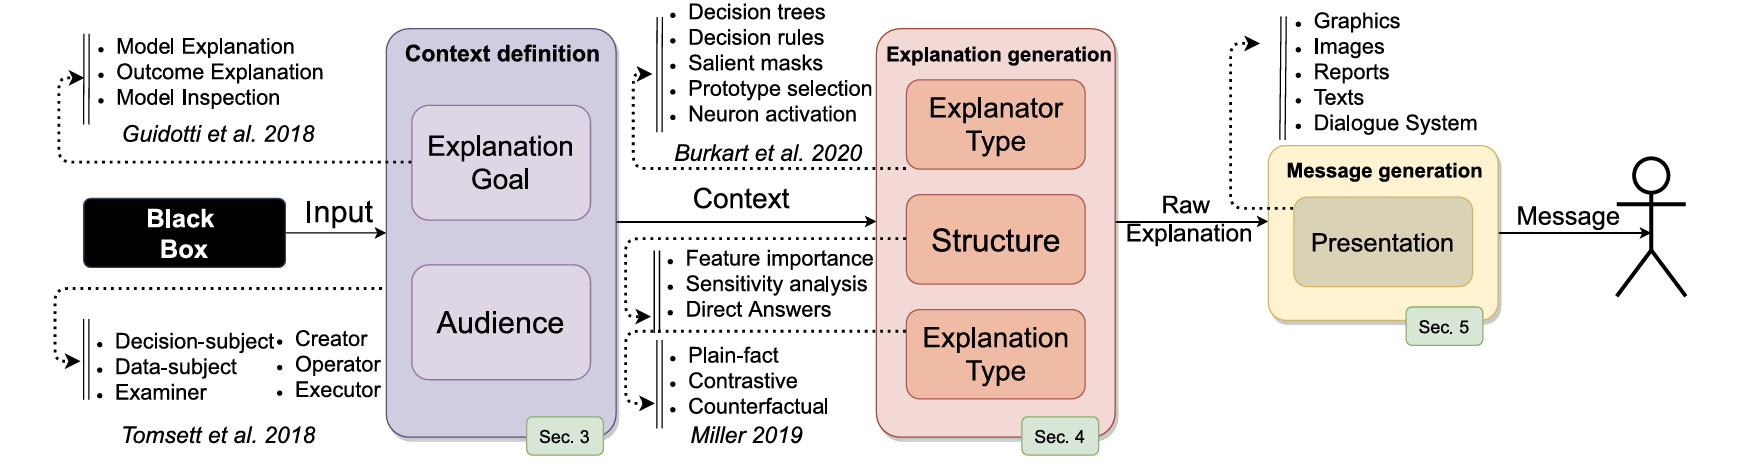

Image from A survey on XAI and natural language explanations (Cambria et al.)

# Explanation scope

## Global explanations

Global summaries describe behavior over a **specified population or reference sample**, not necessarily every possible input. Examples include average attribution magnitudes, performance changes under feature permutation, and surrogate rules evaluated over that sample.

The forest importance chart below summarizes normalized reductions in training impurity. It is not held-out permutation importance and can be affected by feature cardinality and correlated predictors. A model's exact structure can describe its entire mapping, but an estimated global explanation generally provides a limited summary.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Create and train the RandomForest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)

# Get the feature importances
importances = model.feature_importances_

# Sort the feature importances in descending order:
# The following line is a compact way to obtain the indices
# of the elements in importances sorted from the highest importance to the lowest. 
indices = np.argsort(importances)[::-1]

# Reorder the feature names according to the importances
sorted_feature_names = [iris.feature_names[i] for i in indices]

# Plot the feature importances of the forest
plt.figure()
plt.title("Feature Importances")
plt.bar(range(X.shape[1]), importances[indices], color="r", align="center")
# Use the sorted feature names for the x-ticks
plt.xticks(range(X.shape[1]), sorted_feature_names, rotation=90)
plt.xlim([-1, X.shape[1]])
plt.show()

## Local explanations

Local methods describe a selected prediction or neighborhood. State which model output/class is explained, which input is selected and how the neighborhood or baseline is defined. A contribution relative to a reference is not automatically the reason for a real-world event or evidence that an intervention will work.

Let's see an example of SHAP library, used to generate a local explanation:

In [ ]:
import pandas as pd

temp = pd.DataFrame(X, columns=iris.feature_names)
temp['target'] = y

In [ ]:
temp

In [ ]:
y

In [ ]:
import xgboost
import shap
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# A bundled regression dataset keeps this local explanation self-contained.
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = xgboost.XGBRegressor(n_estimators=100, max_depth=3, random_state=42).fit(X_train, y_train)

shap.initjs()
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
# Explain the fifth held-out prediction.
shap.plots.force(shap_values[4], matplotlib=True)

In [ ]:
y

In [ ]:
X_test.iloc[4, :]

The force plot attributes the fifth held-out diabetes-regression prediction. Red contributions raise the **model's predicted response** relative to the explanation baseline; blue contributions lower it. These are model attributions, not causal effects on disease progression.

**Base value:** TreeExplainer's reference output under its tree-path-dependent background. Together with the signed SHAP values it reconstructs the model output. Here both baseline and contributions have diabetes-regression response units. Classification explanations can instead use probabilities or margins/logits; inspect the explainer rather than assuming a scale. The baseline is not generally an observed target mean or a model intercept.

**SHAP contributions:** add the feature contributions to the base value to reconstruct the explained output. The allocation depends on how missing features are represented and how feature dependence is handled. Changing the background or output transformation changes the explanation question. See the [checked SHAP example](../Tools/SHAP_examples/How%20SHAP%20works.md) for an explicit arithmetic example.

In [ ]:
shap.plots.waterfall(shap_values[4])

# Explanation questions

A direct description might report which measured features contribute to a selected prediction. A contrastive question asks “why this prediction rather than that alternative?” A counterfactual input is one way to answer it: find another feature vector to which the **model** assigns the desired output.

For a toy model with approval determined solely by credit score >= 600, an input with score 580 is rejected and an input with 600 is approved. A more complex predictor may have additional conditions; this toy statement cannot be transferred to it without checking the model.

The following DiCE example searches for inputs that flip an income classifier's prediction. It does not establish a minimal change, a feasible personal action, or a causal effect on actual income. Constraints and causal assumptions need to be specified separately. [DiCE method and limitations](../Tools/DiCE_examples/How%20DiCE%20works.md).

In [ ]:
#pip install dice-ml

In [ ]:
import dice_ml
from dice_ml.utils import helpers
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

# This first call downloads the Adult Income dataset from UCI.
dataset = helpers.load_adult_income_dataset()
train_dataset, test_dataset = train_test_split(
    dataset, test_size=0.2, random_state=42, stratify=dataset['income']
)
continuous_features = ['age', 'hours_per_week']
X_train = train_dataset.drop(columns='income')
categorical_features = X_train.columns.drop(continuous_features).tolist()
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('continuous', 'passthrough', continuous_features),
])
# The same pipeline preprocesses training data and DiCE's candidate rows.
classifier = make_pipeline(
    preprocessor, RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42)
)
classifier.fit(X_train, train_dataset['income'])
d = dice_ml.Data(dataframe=train_dataset, continuous_features=continuous_features, outcome_name='income')
m = dice_ml.Model(model=classifier, backend='sklearn')
exp = dice_ml.Dice(d, m, method='random')

In [ ]:
# Generate counterfactual examples
query_instance = test_dataset.drop(columns="income")[0:1]
dice_exp = exp.generate_counterfactuals(query_instance,
                                        total_CFs=4,
                                        desired_class="opposite",
                                        random_seed=42)
# Visualize counterfactual explanation
dice_exp.visualize_as_dataframe()

## Contrastive interpretation and recourse

Read each generated candidate together with the original row and its model prediction. Which coordinates changed, and which were held fixed? Did the desired prediction actually occur? Are the proposed combinations plausible?

A counterfactual feature vector answers a model-level what-if question. An action plan additionally needs constraints, costs and knowledge about how changing one feature affects others. Counterfactual and contrastive explanations are therefore related, not disjoint categories, and neither guarantees a causal recommendation. Compare the constrained search in the [DiCE notebook](../Tools/DiCE_examples/DiCE_example.ipynb).